# Ensino Médio: modalidade, dependência administrativa e rendimento (INEP, 2011–2025)

Notebook exploratório para escolher o recorte do pôster de Inglês 2.

**Unidade de análise.** Escola-ano do Ensino Médio com matrícula > 0 e rendimento informado (as mesmas 426.129 escolas-ano do relatório anterior).

**Regras usadas (iguais às do relatório `exploracao_por_modalidade.py`):**
- `p` = matrículas integrais ÷ (regulares + integrais), por escola-ano.
- Modalidade pela **Regra B** (tolerância de 5%): Regular se p ≤ 5%, Integral se p ≥ 95%, Misto no meio.
- Dependência agrupada: Federal, Estadual/Municipal, Privada.
- Taxas de reprovação e abandono = quantidade ÷ matrículas × 100.
- Gráficos de distribuição por escola usam o corte de porte de **30 matrículas/ano**. Escolas muito pequenas geram taxas extremas (1 aluno = 100%).

**Cuidados que valem para todo o notebook:**
1. 2020–2021 (pandemia) tiveram aprovação quase automática em muitas redes. Esses anos aparecem sombreados nos gráficos de tempo.
2. As escolas integrais se concentram nos anos recentes, quando as taxas caíram em todas as redes. Comparar integral × regular sem controlar o ano mistura efeito da modalidade com efeito do tempo (seção E).
3. Associação não é causa. Este notebook descreve distribuições; não estima efeito causal.

## 0. Leitura e preparação

In [18]:
%pip install Jinja2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
from pathlib import Path
import zipfile

# Pasta onde está o ZIP
PASTA_DADOS = Path(
    r"C:\Users\Yasmin\IMPA TECH\2º. ano\2.2\PICME\Fase1\ED-Dados-INEP\01. Dados"
)

# Caminho do arquivo ZIP
CAMINHO_ZIP = PASTA_DADOS / "bd5.zip"

# Verificar se o arquivo existe
if not CAMINHO_ZIP.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {CAMINHO_ZIP}")

# Extrair
with zipfile.ZipFile(CAMINHO_ZIP, "r") as arquivo_zip:
    print("Arquivos encontrados:", arquivo_zip.namelist())
    arquivo_zip.extractall(PASTA_DADOS)

print("Extração concluída!")

Arquivos encontrados: ['bd5.csv']
Extração concluída!


In [8]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Caminho da base: aceita o bd5.csv ou o bd5.zip do repositório
CAMINHO_BASE = PASTA_DADOS / "bd5.csv"
PASTA_FIG = Path("figuras_EM")
PASTA_FIG.mkdir(exist_ok=True)

MIN_MAT = 30            # corte de porte para gráficos por escola
TOL = 0.05              # tolerância da Regra B
PANDEMIA = (2020, 2021)

ORDEM_MOD = ["Regular", "Misto", "Integral"]
ORDEM_DEP = ["Federal", "Estadual/Municipal", "Privada"]

# Cores validadas para daltonismo (todas as combinações, fundo claro).
COR_MOD = {"Regular": "#2a78d6", "Misto": "#eb6834", "Integral": "#1baf7a"}
COR_DEP = {"Federal": "#6250d6", "Estadual/Municipal": "#008300", "Privada": "#e34948"}
ESTILO_DEP = {"Federal": "-", "Estadual/Municipal": "--", "Privada": ":"}  # codificação extra além da cor
TINTA, TINTA2, MUDO, GRADE, EIXO = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": EIXO, "axes.labelcolor": TINTA2,
    "axes.titlecolor": TINTA, "axes.titlesize": 12, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRADE, "grid.linewidth": 0.6,
    "xtick.color": MUDO, "ytick.color": MUDO, "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2,
    "legend.frameon": False, "font.family": "sans-serif", "font.size": 10, "lines.linewidth": 2,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def sombrear_pandemia(ax):
    ax.axvspan(PANDEMIA[0] - 0.5, PANDEMIA[1] + 0.5, color=GRADE, alpha=0.5, lw=0, zorder=0)


def rotulo_final(ax, x, y, texto, cor):
    # guarda o rótulo; desenhado por rotular(ax) depois que todas as linhas existem
    ax._rotulos = getattr(ax, "_rotulos", []) + [(x, y, texto)]


def rotular(ax, folga=0.055):
    # rótulos diretos no fim das linhas, afastados verticalmente para não se sobreporem
    itens = sorted(getattr(ax, "_rotulos", []), key=lambda r: r[1])
    if not itens:
        return
    y0, y1 = ax.get_ylim()
    passo = folga * (y1 - y0)
    pos = []
    for _, y, _ in itens:
        pos.append(max(y, pos[-1] + passo) if pos else y)
    for (x, _, texto), yp in zip(itens, pos):
        ax.text(x + 0.35, yp, texto, va="center", ha="left", fontsize=9, color=TINTA2, clip_on=False)
    ax._rotulos = []


def salvar(fig, nome):
    for ax in fig.axes:
        rotular(ax)
    fig.savefig(PASTA_FIG / f"{nome}.png", bbox_inches="tight")

In [9]:
COLS = ["ANO", "CO_ESCOLA", "UF", "REGIAO", "LOCALIZACAO", "DEP_ADM",
        "QT_MAT_EM_REG", "QT_MAT_EM_INT", "QT_APR_EM_TOTAL", "QT_REP_EM_TOTAL", "QT_ABN_EM_TOTAL"]

if CAMINHO_BASE.suffix == ".zip":
    with zipfile.ZipFile(CAMINHO_BASE) as z:
        nome_csv = [n for n in z.namelist() if n.endswith(".csv")][0]
        with z.open(nome_csv) as f:
            bruto = pd.read_csv(f, sep=";", encoding="utf-8-sig", usecols=COLS, low_memory=False)
else:
    bruto = pd.read_csv(CAMINHO_BASE, sep=";", encoding="utf-8-sig", usecols=COLS, low_memory=False)

df = bruto.rename(columns={
    "ANO": "ano", "CO_ESCOLA": "escola", "UF": "uf", "REGIAO": "regiao", "LOCALIZACAO": "localizacao",
    "DEP_ADM": "dep_original", "QT_MAT_EM_REG": "mat_reg", "QT_MAT_EM_INT": "mat_int",
    "QT_APR_EM_TOTAL": "apr", "QT_REP_EM_TOTAL": "rep", "QT_ABN_EM_TOTAL": "abn"})
for c in ["mat_reg", "mat_int", "apr", "rep", "abn"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df["mat"] = df["mat_reg"].fillna(0) + df["mat_int"].fillna(0)
n_linhas = len(df)
df = df[df["mat"] > 0]
n_mat = len(df)
df = df[df[["apr", "rep", "abn"]].notna().any(axis=1)].copy()

df["p_int"] = df["mat_int"].fillna(0) / df["mat"]
df["modalidade"] = pd.Categorical(
    np.select([df["p_int"] >= 1 - TOL, df["p_int"] > TOL], ["Integral", "Misto"], "Regular"),
    categories=ORDEM_MOD)
df["dependencia"] = pd.Categorical(
    df["dep_original"].str.lower().map({"federal": "Federal", "estadual": "Estadual/Municipal",
                                         "municipal": "Estadual/Municipal", "privada": "Privada"}),
    categories=ORDEM_DEP)
for t in ["apr", "rep", "abn"]:
    df[f"tx_{t}"] = df[t] / df["mat"] * 100
df["porte_ok"] = df["mat"] >= MIN_MAT

print(f"Linhas na base:                  {n_linhas:>10,}".replace(",", "."))
print(f"Escolas-ano com matrícula no EM: {n_mat:>10,}".replace(",", "."))
print(f"Com rendimento (analisadas):     {len(df):>10,}".replace(",", "."))
print(f"  com ≥ {MIN_MAT} matrículas:          {df['porte_ok'].sum():>10,}".replace(",", "."))
print(f"Escolas distintas:               {df['escola'].nunique():>10,}".replace(",", "."))

Linhas na base:                   2.051.631
Escolas-ano com matrícula no EM:    429.002
Com rendimento (analisadas):        426.129
  com ≥ 30 matrículas:             402.083
Escolas distintas:                   36.851


In [10]:
# Conferência com o relatório anterior (Regra B, escolas-ano)
pd.crosstab(df["dependencia"], df["modalidade"], margins=True, margins_name="Total")

modalidade,Regular,Misto,Integral,Total
dependencia,,,,
Federal,3808,936,2909,7653
Estadual/Municipal,237222,32553,25889,295664
Privada,114095,3212,5505,122812
Total,355125,36701,34303,426129


## A. Evolução da modalidade (2011–2025)

Três leituras do mesmo fenômeno: número de escolas, participação das escolas e participação das matrículas. Elas não andam exatamente juntas porque as escolas integrais são um pouco menores que as regulares (seção E3).

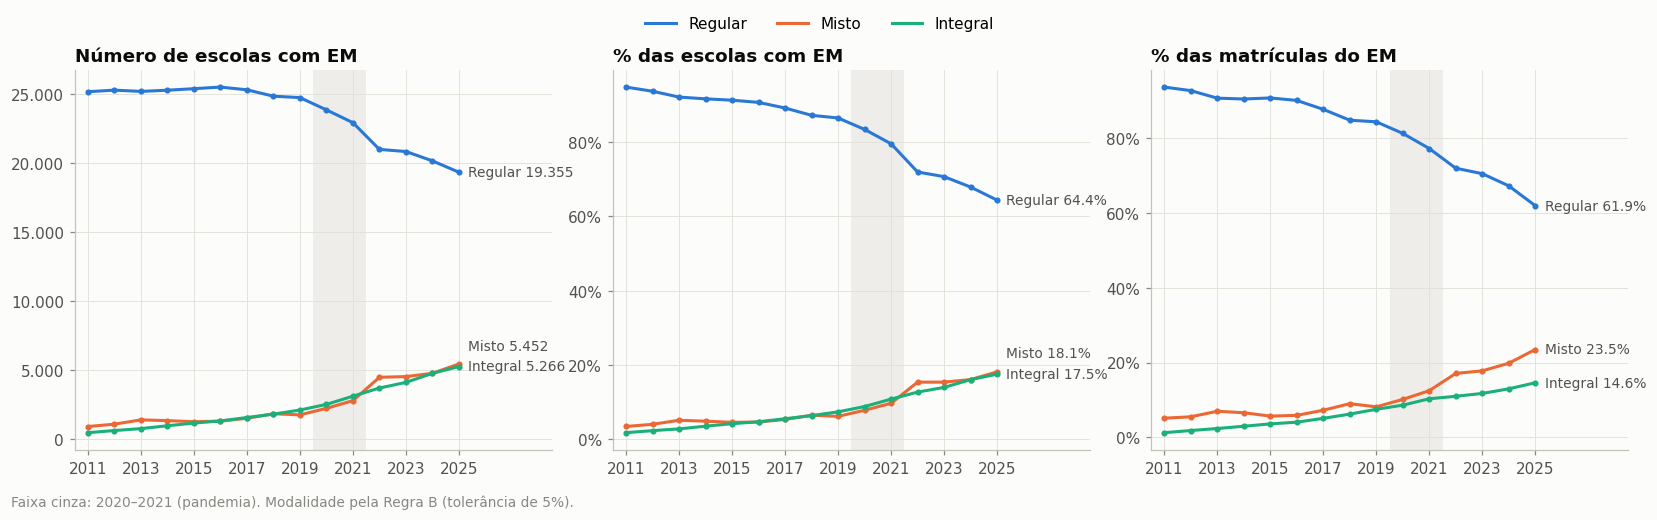

escolas                % escolas                % matrículas               
modalidade Regular Misto Integral   Regular Misto Integral      Regular Misto Integral
ano                                                                                   
2011         25191   914      470      94.8   3.4      1.8         93.6   5.1      1.3
2012         25306  1086      625      93.7   4.0      2.3         92.7   5.5      1.8
2013         25213  1398      764      92.1   5.1      2.8         90.7   7.0      2.4
2014         25300  1342      970      91.6   4.9      3.5         90.4   6.6      3.0
2015         25411  1266     1166      91.3   4.5      4.2         90.7   5.7      3.6
2016         25527  1305     1322      90.7   4.6      4.7         90.0   5.9      4.1
2017         25330  1513     1568      89.2   5.3      5.5         87.7   7.3      5.1
2018         24867  1841     1813      87.2   6.5      6.4         84.8   9.0      6.2
2019         24765  1761     2111      86.5   6.1      7.4         84.3   8.2      7.5
2020         23875  2233     2521      83.4   7.8      8.8         81.2  10.2      8.6
2021         22945  2793     3115      79.5   9.7     10.8         77.2  12.5     10.3
2022         21007  4486     3707      71.9  15.4     12.7         71.9  17.1     11.0
2023         20856  4536     4115      70.7  15.4     13.9         70.5  17.8     11.7
2024         20177  4775     4770      67.9  16.1     16.0         67.2  19.8     13.0
2025         19355  5452     5266      64.4  18.1     17.5         61.9  23.5     14.6

In [11]:
esc_ano = pd.crosstab(df["ano"], df["modalidade"])
pct_esc = esc_ano.div(esc_ano.sum(axis=1), axis=0) * 100
mat_ano = df.pivot_table(index="ano", columns="modalidade", values="mat", aggfunc="sum", observed=True)
pct_mat = mat_ano.div(mat_ano.sum(axis=1), axis=0) * 100

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, tab, titulo, fmt in [
    (axs[0], esc_ano, "Número de escolas com EM", "{:,.0f}"),
    (axs[1], pct_esc, "% das escolas com EM", "{:.1f}%"),
    (axs[2], pct_mat, "% das matrículas do EM", "{:.1f}%"),
]:
    sombrear_pandemia(ax)
    for m in ORDEM_MOD:
        ax.plot(tab.index, tab[m], color=COR_MOD[m], marker="o", ms=3)
        rotulo_final(ax, tab.index[-1], tab[m].iloc[-1], f"{m} {fmt.format(tab[m].iloc[-1])}".replace(",", "."), COR_MOD[m])
    ax.set_title(titulo)
    ax.set_xlim(2010.5, 2028.5)
    ax.set_xticks(range(2011, 2026, 2))
axs[0].yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
for ax in axs[1:]:
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
fig.legend([plt.Line2D([], [], color=COR_MOD[m], lw=2) for m in ORDEM_MOD], ORDEM_MOD,
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06))
fig.text(0.01, -0.03, "Faixa cinza: 2020–2021 (pandemia). Modalidade pela Regra B (tolerância de 5%).", color=MUDO, fontsize=9)
fig.tight_layout()
salvar(fig, "A1_evolucao_modalidade")
plt.show()

tabela_A = pd.concat({"escolas": esc_ano, "% escolas": pct_esc.round(1), "% matrículas": pct_mat.round(1)}, axis=1)
tabela_A

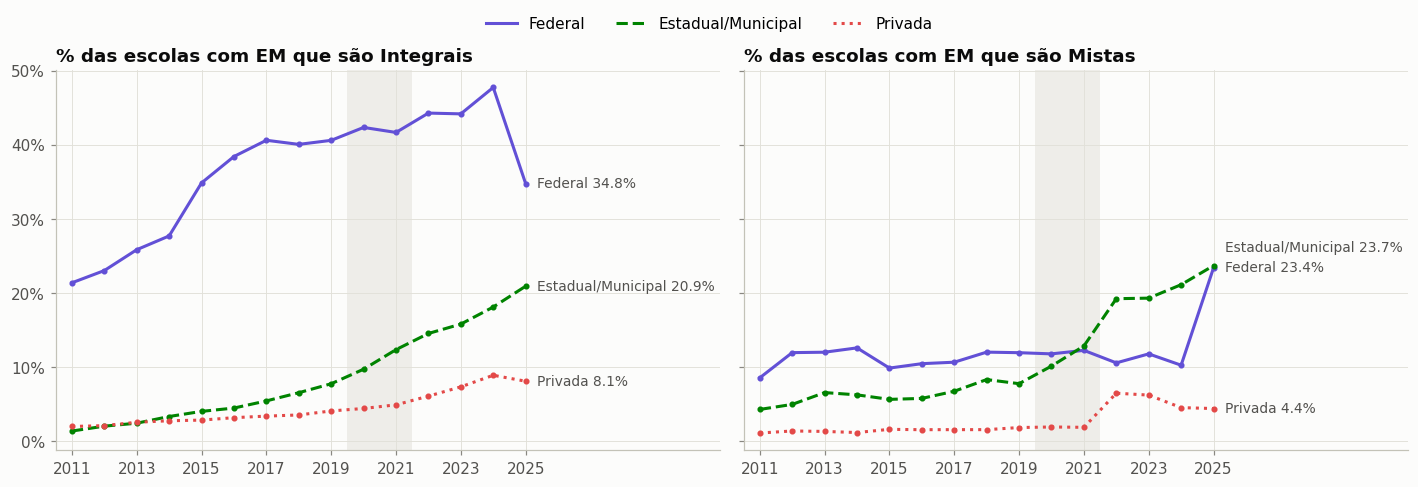

% Integral                            % Misto                           
dependencia    Federal Estadual/Municipal Privada Federal Estadual/Municipal Privada
ano                                                                                 
2011              21.4                1.4     2.0     8.6                4.3     1.1
2012              23.0                2.0     2.1    12.0                5.0     1.4
2013              25.8                2.4     2.6    12.0                6.6     1.3
2014              27.7                3.3     2.8    12.6                6.3     1.2
2015              34.9                4.0     2.8     9.9                5.6     1.6
2016              38.4                4.5     3.2    10.5                5.8     1.5
2017              40.6                5.4     3.4    10.7                6.7     1.6
2018              40.1                6.5     3.5    12.0                8.3     1.6
2019              40.6                7.8     4.1    11.9                7.8     1.8
2020              42.4                9.7     4.4    11.8               10.1     1.9
2021              41.7               12.4     4.9    12.3               12.8     1.9
2022              44.3               14.5     6.1    10.6               19.2     6.5
2023              44.2               15.8     7.3    11.8               19.3     6.2
2024              47.8               18.1     8.9    10.3               21.1     4.5
2025              34.8               20.9     8.1    23.4               23.7     4.4

In [12]:
# % das escolas classificadas como Integral, por dependência
pct_int_dep = (df.assign(integral=df["modalidade"].eq("Integral"))
                 .groupby(["ano", "dependencia"], observed=True)["integral"].mean().unstack() * 100)
pct_mis_dep = (df.assign(misto=df["modalidade"].eq("Misto"))
                 .groupby(["ano", "dependencia"], observed=True)["misto"].mean().unstack() * 100)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, tab, titulo in [(axs[0], pct_int_dep, "% das escolas com EM que são Integrais"),
                        (axs[1], pct_mis_dep, "% das escolas com EM que são Mistas")]:
    sombrear_pandemia(ax)
    for d in ORDEM_DEP:
        ax.plot(tab.index, tab[d], color=COR_DEP[d], ls=ESTILO_DEP[d], marker="o", ms=3)
        rotulo_final(ax, tab.index[-1], tab[d].iloc[-1], f"{d} {tab[d].iloc[-1]:.1f}%", COR_DEP[d])
    ax.set_title(titulo)
    ax.set_xlim(2010.5, 2031)
    ax.set_xticks(range(2011, 2026, 2))
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
fig.legend([plt.Line2D([], [], color=COR_DEP[d], ls=ESTILO_DEP[d], lw=2) for d in ORDEM_DEP], ORDEM_DEP,
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
salvar(fig, "A2_integral_por_dependencia")
plt.show()

pd.concat({"% Integral": pct_int_dep.round(1), "% Misto": pct_mis_dep.round(1)}, axis=1)

**Atenção: Federal em 2025.** O % de integrais federais cai de 47,8% (2024) para 34,8% (2025), e o % de mistas sobe quase o mesmo tanto. Isso parece reclassificação, não mudança real nas escolas. A célula abaixo segue as mesmas escolas federais de 2024 para 2025. Em 2025 as matrículas passaram a vir de outra tabela do Censo (documentação da Dani), o que pode explicar. Até confirmar, é mais seguro **não usar 2025 da rede federal** no pôster.

In [13]:
fed = df[df["dependencia"] == "Federal"]
a = fed[fed["ano"] == 2024].set_index("escola")[["modalidade", "p_int"]]
b = fed[fed["ano"] == 2025].set_index("escola")[["modalidade", "p_int"]]
par = a.join(b, lsuffix="_2024", rsuffix="_2025", how="inner")
print(f"Escolas federais presentes em 2024 e 2025: {len(par)}")
print("\nModalidade 2024 (linhas) × 2025 (colunas):")
display(pd.crosstab(par["modalidade_2024"], par["modalidade_2025"], margins=True))
mud = par[(par["modalidade_2024"] == "Integral") & (par["modalidade_2025"] != "Integral")]
print(f"\nIntegrais em 2024 que deixaram de ser em 2025: {len(mud)}")
print("Proporção integral (p) dessas escolas em 2025, resumo:")
print(mud["p_int_2025"].describe().round(3).to_string())

Escolas federais presentes em 2024 e 2025: 609

Modalidade 2024 (linhas) × 2025 (colunas):


modalidade_2025,Regular,Misto,Integral,All
modalidade_2024,,,,
Regular,215,36,4,255
Misto,15,38,11,64
Integral,23,71,196,290
All,253,145,211,609



Integrais em 2024 que deixaram de ser em 2025: 94
Proporção integral (p) dessas escolas em 2025, resumo:
count    94.000
mean      0.421
std       0.334
min       0.000
25%       0.094
50%       0.404
75%       0.741
max       0.938


## B. Reprovação e abandono × modalidade

**B1** mostra a distribuição entre escolas (cada ponto é uma escola-ano). **B2** mostra a taxa agregada do país em cada ano (soma dos reprovados ÷ soma das matrículas), que pesa as escolas pelo tamanho.

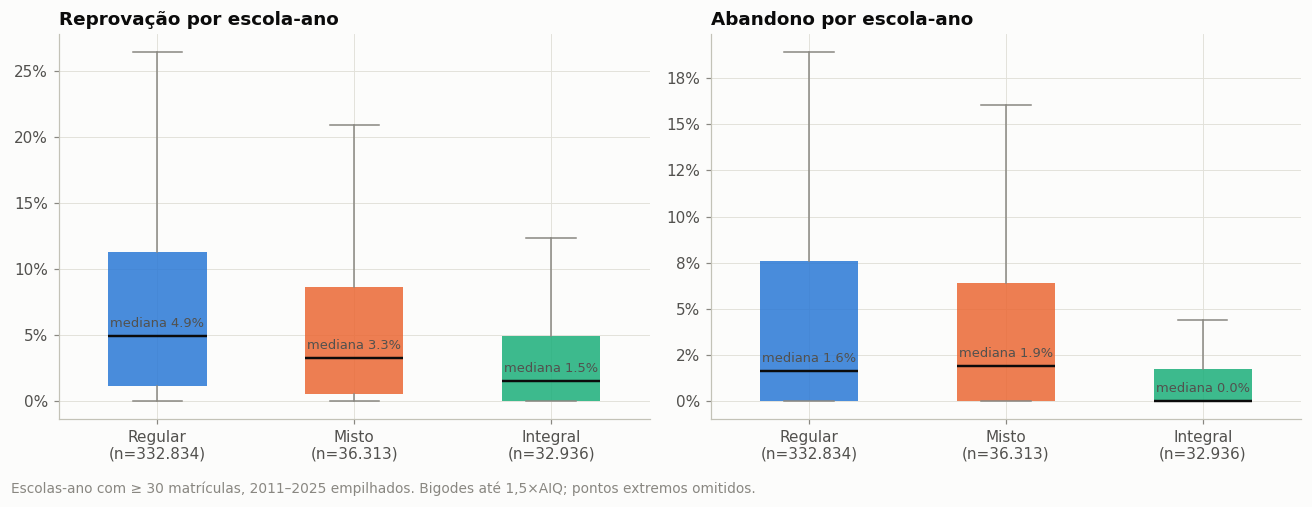

tx_rep                                                tx_abn                                         
               count  mean   std  min   25%   50%    75%     max     count  mean   std  min  25%   50%   75%    max
modalidade                                                                                                         
Regular     332834.0  7.52  8.31  0.0  1.15  4.91  11.26  100.00  332834.0  4.95  7.27  0.0  0.0  1.64  7.57  100.0
Misto        36313.0  5.81  6.98  0.0  0.56  3.29   8.68   60.23   36313.0  4.34  6.13  0.0  0.0  1.90  6.41  100.0
Integral     32936.0  3.60  5.42  0.0  0.00  1.51   4.95   69.57   32936.0  1.82  4.96  0.0  0.0  0.00  1.77  100.0

In [14]:
d30 = df[df["porte_ok"]]

fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, t, titulo in [(axs[0], "tx_rep", "Reprovação por escola-ano"), (axs[1], "tx_abn", "Abandono por escola-ano")]:
    dados = [d30.loc[d30["modalidade"] == m, t].dropna() for m in ORDEM_MOD]
    bp = ax.boxplot(dados, tick_labels=[f"{m}\n(n={len(x):,})".replace(",", ".") for m, x in zip(ORDEM_MOD, dados)],
                    patch_artist=True, showfliers=False, widths=0.5,
                    medianprops=dict(color=TINTA, lw=1.6), whiskerprops=dict(color=MUDO),
                    capprops=dict(color=MUDO), boxprops=dict(lw=0))
    for caixa, m in zip(bp["boxes"], ORDEM_MOD):
        caixa.set_facecolor(COR_MOD[m]); caixa.set_alpha(0.85)
    for i, x in enumerate(dados, 1):
        ax.annotate(f"mediana {x.median():.1f}%", (i, x.median()), xytext=(0, 6),
                    textcoords="offset points", ha="center", fontsize=8.5, color=TINTA2)
    ax.set_title(titulo)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
fig.text(0.01, -0.03, f"Escolas-ano com ≥ {MIN_MAT} matrículas, 2011–2025 empilhados. Bigodes até 1,5×AIQ; pontos extremos omitidos.", color=MUDO, fontsize=9)
fig.tight_layout()
salvar(fig, "B1_boxplot_rep_abn_modalidade")
plt.show()

d30.groupby("modalidade", observed=True)[["tx_rep", "tx_abn"]].describe(percentiles=[.25, .5, .75]).round(2)

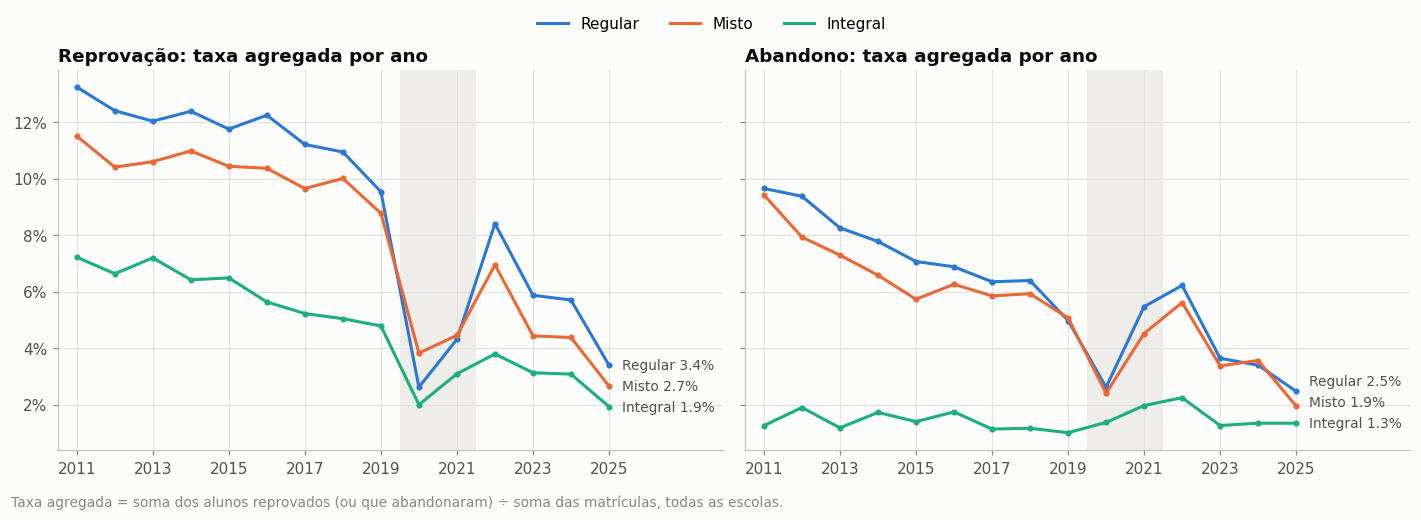

Reprovação                Abandono               
modalidade    Regular Misto Integral  Regular Misto Integral
ano                                                         
2011             13.2  11.5      7.2      9.6   9.4      1.3
2012             12.4  10.4      6.6      9.4   7.9      1.9
2013             12.0  10.6      7.2      8.3   7.3      1.2
2014             12.4  11.0      6.4      7.8   6.6      1.7
2015             11.7  10.4      6.5      7.1   5.7      1.4
2016             12.2  10.4      5.6      6.9   6.3      1.7
2017             11.2   9.6      5.2      6.3   5.8      1.1
2018             10.9  10.0      5.0      6.4   5.9      1.2
2019              9.5   8.8      4.8      5.0   5.1      1.0
2020              2.6   3.8      2.0      2.6   2.4      1.4
2021              4.3   4.4      3.1      5.5   4.5      2.0
2022              8.4   6.9      3.8      6.2   5.6      2.2
2023              5.9   4.4      3.1      3.6   3.4      1.3
2024              5.7   4.4      3.1      3.4   3.6      1.3
2025              3.4   2.7      1.9      2.5   1.9      1.3

In [15]:
agg = df.groupby(["ano", "modalidade"], observed=True)[["mat", "rep", "abn"]].sum()
agg["Reprovação"] = agg["rep"] / agg["mat"] * 100
agg["Abandono"] = agg["abn"] / agg["mat"] * 100

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, t in zip(axs, ["Reprovação", "Abandono"]):
    tab = agg[t].unstack()
    sombrear_pandemia(ax)
    for m in ORDEM_MOD:
        ax.plot(tab.index, tab[m], color=COR_MOD[m], marker="o", ms=3)
        rotulo_final(ax, tab.index[-1], tab[m].iloc[-1], f"{m} {tab[m].iloc[-1]:.1f}%", COR_MOD[m])
    ax.set_title(f"{t}: taxa agregada por ano")
    ax.set_xlim(2010.5, 2028)
    ax.set_xticks(range(2011, 2026, 2))
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
fig.legend([plt.Line2D([], [], color=COR_MOD[m], lw=2) for m in ORDEM_MOD], ORDEM_MOD,
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06))
fig.text(0.01, -0.03, "Taxa agregada = soma dos alunos reprovados (ou que abandonaram) ÷ soma das matrículas, todas as escolas.", color=MUDO, fontsize=9)
fig.tight_layout()
salvar(fig, "B2_taxas_por_ano_modalidade")
plt.show()

agg[["Reprovação", "Abandono"]].unstack().round(1)

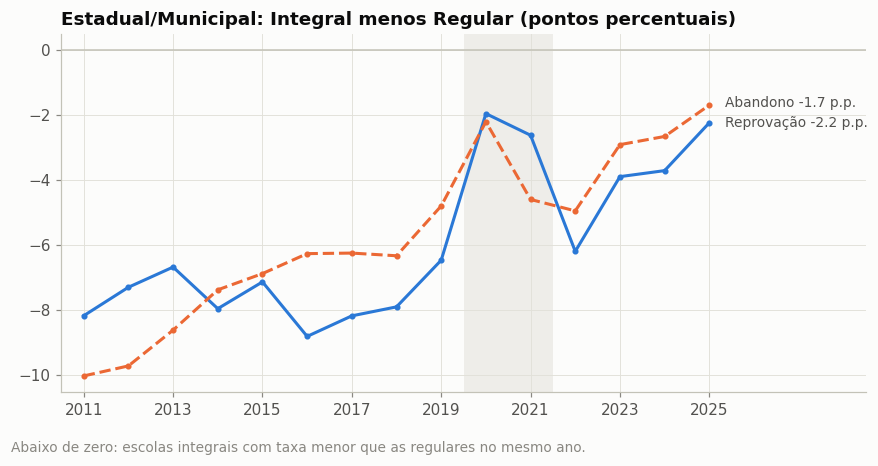

,Reprovação,Abandono
ano,,
2011,-8.16,-10.02
2012,-7.29,-9.71
2013,-6.67,-8.61
2014,-7.95,-7.37
2015,-7.12,-6.87
2016,-8.80,-6.25
2017,-8.17,-6.24
2018,-7.89,-6.32
2019,-6.46,-4.79


In [16]:
# Diferença Integral − Regular, por ano, só na rede Estadual/Municipal (onde está a expansão)
em = df[df["dependencia"] == "Estadual/Municipal"]
g = em.groupby(["ano", "modalidade"], observed=True)[["mat", "rep", "abn"]].sum()
g["rep%"] = g["rep"] / g["mat"] * 100
g["abn%"] = g["abn"] / g["mat"] * 100
gap = pd.DataFrame({
    "Reprovação": g["rep%"].xs("Integral", level=1) - g["rep%"].xs("Regular", level=1),
    "Abandono": g["abn%"].xs("Integral", level=1) - g["abn%"].xs("Regular", level=1),
})

fig, ax = plt.subplots(figsize=(8, 4))
sombrear_pandemia(ax)
ax.axhline(0, color=EIXO, lw=1)
for t, cor, ls in [("Reprovação", "#2a78d6", "-"), ("Abandono", "#eb6834", "--")]:
    ax.plot(gap.index, gap[t], color=cor, ls=ls, marker="o", ms=3)
    rotulo_final(ax, gap.index[-1], gap[t].iloc[-1], f"{t} {gap[t].iloc[-1]:+.1f} p.p.", cor)
ax.set_title("Estadual/Municipal: Integral menos Regular (pontos percentuais)")
ax.set_xlim(2010.5, 2028.5)
ax.set_xticks(range(2011, 2026, 2))
fig.text(0.01, -0.04, "Abaixo de zero: escolas integrais com taxa menor que as regulares no mesmo ano.", color=MUDO, fontsize=9)
fig.tight_layout()
salvar(fig, "B3_diferenca_integral_regular_estmun")
plt.show()
gap.round(2)

## C. Correlação entre modalidade e rendimento

**O problema.** Modalidade é uma variável categórica (Regular, Misto, Integral). Correlação de Pearson pede duas variáveis numéricas. Há três formas razoáveis de medir a associação, e o notebook calcula as três:

1. **Spearman com `p`** (proporção de matrículas integrais, de 0 a 1). Usa a informação contínua por trás da modalidade. É a medida principal.
2. **Spearman com a modalidade como ordem** (Regular = 0, Misto = 1, Integral = 2).
3. **Kruskal-Wallis + ε²** (epsilon ao quadrado): testa se as distribuições dos três grupos diferem e diz quanto da variação das taxas acompanha a modalidade (de 0 a 1).

**Como ler.** Com 400 mil escolas-ano, qualquer diferença minúscula dá p-valor ≈ 0. O que importa é o tamanho: |ρ| < 0,1 é desprezível, 0,1–0,3 é fraco, 0,3–0,5 é moderado.

In [19]:
def epsilon2(grupos):
    grupos = [g for g in grupos if len(g) > 0]
    H, p = stats.kruskal(*grupos)
    n = sum(len(g) for g in grupos)
    return H, p, (H - len(grupos) + 1) / (n - len(grupos))


ORD = {"Regular": 0, "Misto": 1, "Integral": 2}
linhas = []
recortes = [("Todas as redes", d30)] + [(d, d30[d30["dependencia"] == d]) for d in ORDEM_DEP]
for nome, s in recortes:
    for t, rot in [("tx_rep", "Reprovação"), ("tx_abn", "Abandono")]:
        x = s[["p_int", "modalidade", t]].dropna()
        rho_p = stats.spearmanr(x["p_int"], x[t]).statistic
        rho_o = stats.spearmanr(x["modalidade"].map(ORD).astype(int), x[t]).statistic
        H, pv, e2 = epsilon2([x.loc[x["modalidade"] == m, t] for m in ORDEM_MOD])
        linhas.append({"recorte": nome, "taxa": rot, "n": len(x),
                       "ρ Spearman (p)": rho_p, "ρ Spearman (ordem)": rho_o, "ε² Kruskal-Wallis": e2})
correl = pd.DataFrame(linhas).set_index(["recorte", "taxa"])
correl.style.format({"n": "{:,.0f}", "ρ Spearman (p)": "{:+.3f}", "ρ Spearman (ordem)": "{:+.3f}",
                     "ε² Kruskal-Wallis": "{:.3f}"})

**Por que o resultado muda tanto entre "todas as redes" e "Estadual/Municipal"?** Ao juntar as redes, a correlação mistura duas coisas: escolas privadas regulares têm reprovação e abandono baixos, e as federais têm muita matrícula integral com reprovação relativamente alta. Isso dilui a associação. Dentro da rede Estadual/Municipal, que é onde a política de expansão aconteceu, a associação negativa aparece mais clara.

O mesmo vale para o tempo: as integrais se concentram nos anos recentes, quando as taxas caíram para todo mundo. A célula abaixo calcula a correlação **dentro de cada ano**, o que remove o efeito do tempo.

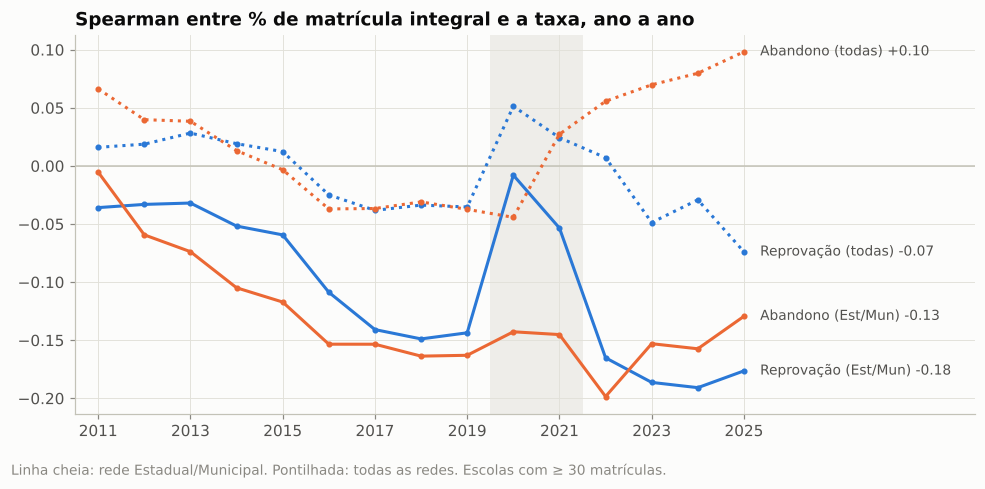

,Reprovação (Est/Mun),Abandono (Est/Mun),Reprovação (todas),Abandono (todas)
ano,,,,
2011,-0.036,-0.005,0.016,0.066
2012,-0.033,-0.059,0.019,0.040
2013,-0.032,-0.074,0.028,0.038
2014,-0.052,-0.105,0.019,0.013
2015,-0.059,-0.117,0.012,-0.003
2016,-0.109,-0.153,-0.025,-0.037
2017,-0.141,-0.153,-0.038,-0.037
2018,-0.149,-0.164,-0.034,-0.031
2019,-0.144,-0.163,-0.035,-0.037


In [ ]:
def rho_ano(s, t):
    return s.groupby("ano").apply(lambda x: stats.spearmanr(x["p_int"], x[t], nan_policy="omit").statistic)

em30 = d30[d30["dependencia"] == "Estadual/Municipal"]
rho_por_ano = pd.DataFrame({
    "Reprovação (Est/Mun)": rho_ano(em30, "tx_rep"),
    "Abandono (Est/Mun)": rho_ano(em30, "tx_abn"),
    "Reprovação (todas)": rho_ano(d30, "tx_rep"),
    "Abandono (todas)": rho_ano(d30, "tx_abn"),
})

fig, ax = plt.subplots(figsize=(9, 4.2))
sombrear_pandemia(ax)
ax.axhline(0, color=EIXO, lw=1)
for col, cor, ls in [("Reprovação (Est/Mun)", "#2a78d6", "-"), ("Abandono (Est/Mun)", "#eb6834", "-"),
                     ("Reprovação (todas)", "#2a78d6", ":"), ("Abandono (todas)", "#eb6834", ":")]:
    ax.plot(rho_por_ano.index, rho_por_ano[col], color=cor, ls=ls, marker="o", ms=3)
    rotulo_final(ax, rho_por_ano.index[-1], rho_por_ano[col].iloc[-1], f"{col} {rho_por_ano[col].iloc[-1]:+.2f}", cor)
ax.set_title("Spearman entre % de matrícula integral e a taxa, ano a ano")
ax.set_xlim(2010.5, 2030)
ax.set_xticks(range(2011, 2026, 2))
fig.text(0.01, -0.04, f"Linha cheia: rede Estadual/Municipal. Pontilhada: todas as redes. Escolas com ≥ {MIN_MAT} matrículas.", color=MUDO, fontsize=9)
fig.tight_layout()
salvar(fig, "C1_spearman_por_ano")
plt.show()
rho_por_ano.round(3)

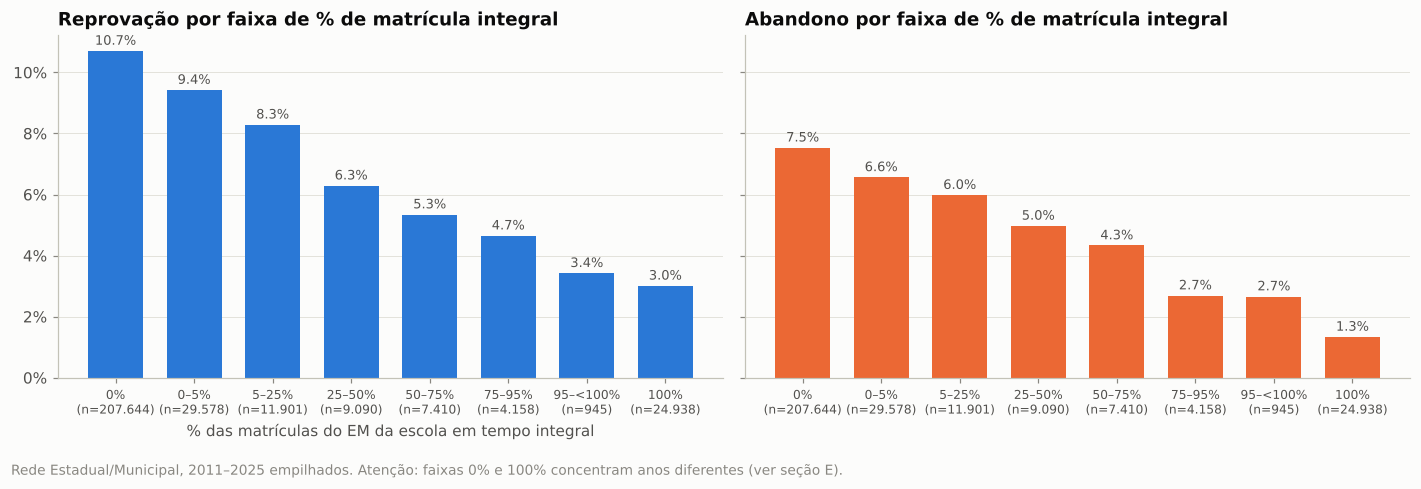

,mat,rep,abn,Reprovação,Abandono,escolas-ano
faixa,,,,,,
0%,67630792,7239589.0,5095542.0,10.70,7.53,207644
0–5%,15134555,1426268.0,993379.0,9.42,6.56,29578
5–25%,4704334,389859.0,281388.0,8.29,5.98,11901
25–50%,2998029,188615.0,149136.0,6.29,4.97,9090
50–75%,2410251,128815.0,104398.0,5.34,4.33,7410
75–95%,1418209,65993.0,38160.0,4.65,2.69,4158
95–<100%,263105,9009.0,6996.0,3.42,2.66,945
100%,6222502,187328.0,83248.0,3.01,1.34,24938


In [ ]:
# Visual da relação: taxa agregada por faixa de % integral (rede Estadual/Municipal)
cortes = [-0.001, 0, 0.05, 0.25, 0.5, 0.75, 0.95, 0.999999, 1]
rotulos = ["0%", "0–5%", "5–25%", "25–50%", "50–75%", "75–95%", "95–<100%", "100%"]
em_f = em.assign(faixa=pd.cut(em["p_int"], cortes, labels=rotulos))
fx = em_f.groupby("faixa", observed=True)[["mat", "rep", "abn"]].sum()
fx["Reprovação"] = fx["rep"] / fx["mat"] * 100
fx["Abandono"] = fx["abn"] / fx["mat"] * 100
fx["escolas-ano"] = em_f.groupby("faixa", observed=True).size()

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, t, cor in [(axs[0], "Reprovação", "#2a78d6"), (axs[1], "Abandono", "#eb6834")]:
    barras = ax.bar(range(len(fx)), fx[t], color=cor, width=0.7)
    ax.bar_label(barras, labels=[f"{v:.1f}%" for v in fx[t]], fontsize=8.5, color=TINTA2, padding=2)
    ax.set_xticks(range(len(fx)), [f"{r}\n(n={n:,})".replace(",", ".") for r, n in zip(fx.index, fx["escolas-ano"])], fontsize=8)
    ax.set_title(f"{t} por faixa de % de matrícula integral")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.grid(axis="x", visible=False)
axs[0].set_xlabel("% das matrículas do EM da escola em tempo integral", color=TINTA2)
fig.text(0.01, -0.04, "Rede Estadual/Municipal, 2011–2025 empilhados. Atenção: faixas 0% e 100% concentram anos diferentes (ver seção E).", color=MUDO, fontsize=9)
fig.tight_layout()
salvar(fig, "C2_taxa_por_faixa_integral")
plt.show()
fx.round(2)

## D. Dependência administrativa (Federal, Estadual/Municipal, Privada)

**D1** cruza dependência × modalidade com as taxas por escola-ano. **D2** usa a unidade do abstract: taxa **acumulada em 2011–2025**, calculada por escola × período em cada modalidade (a "versão 5" do relatório anterior). **D3** mostra as tendências por rede.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


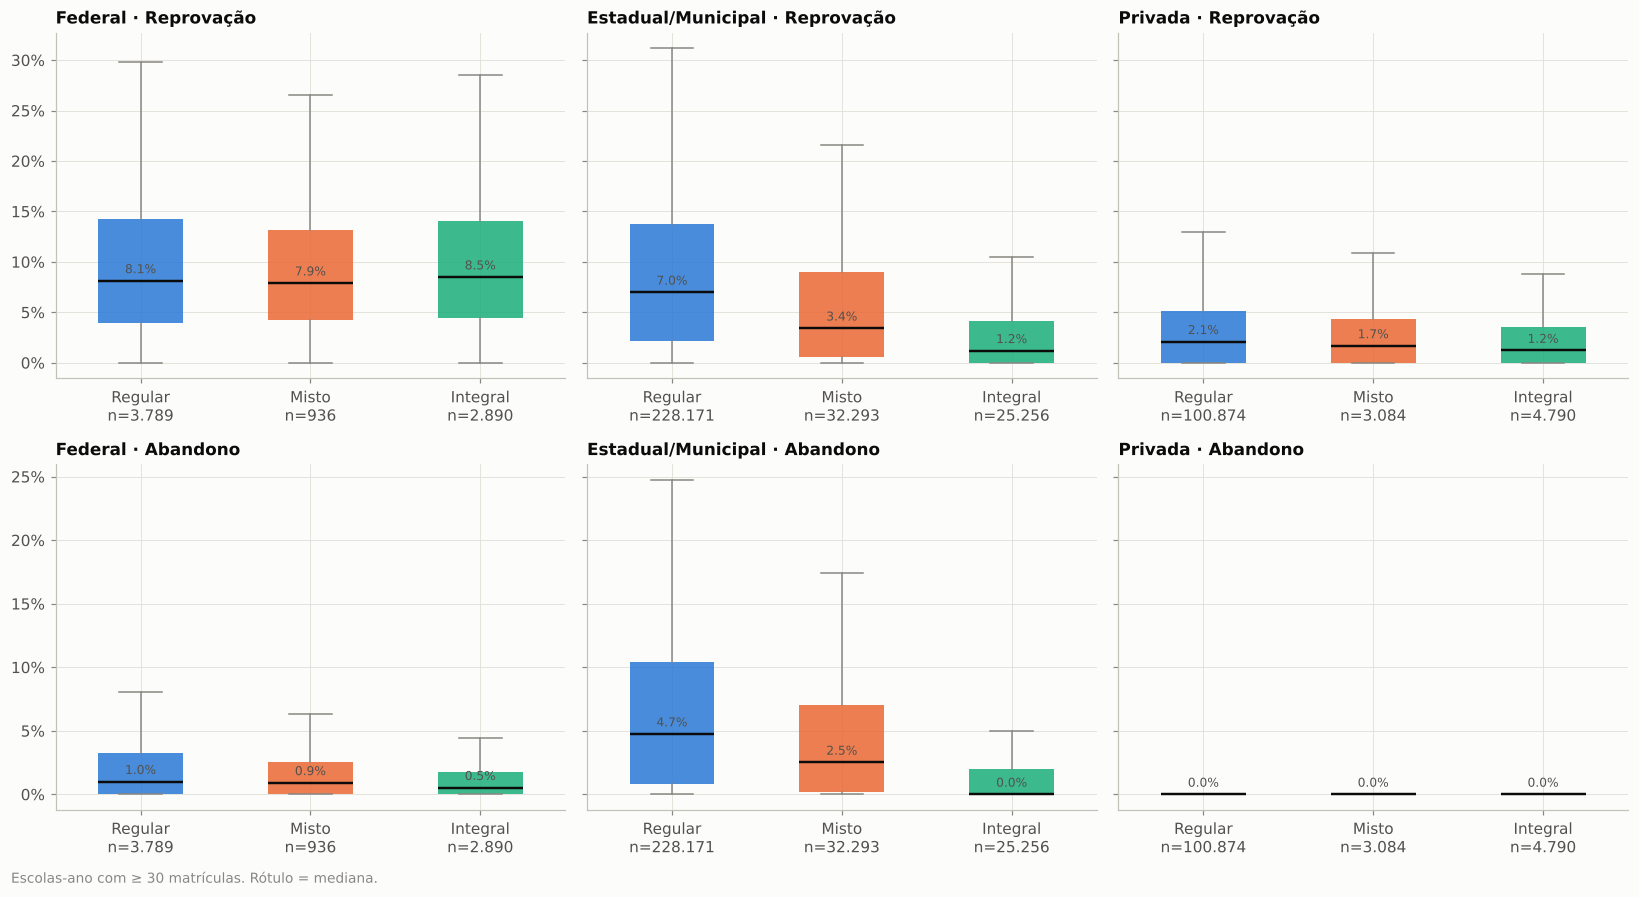

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharey="row")
for j, dep in enumerate(ORDEM_DEP):
    s = d30[d30["dependencia"] == dep]
    for i, (t, rot) in enumerate([("tx_rep", "Reprovação"), ("tx_abn", "Abandono")]):
        ax = axs[i, j]
        dados = [s.loc[s["modalidade"] == m, t].dropna() for m in ORDEM_MOD]
        bp = ax.boxplot(dados, tick_labels=[f"{m}\nn={len(x):,}".replace(",", ".") for m, x in zip(ORDEM_MOD, dados)],
                        patch_artist=True, showfliers=False, widths=0.5,
                        medianprops=dict(color=TINTA, lw=1.6), whiskerprops=dict(color=MUDO),
                        capprops=dict(color=MUDO), boxprops=dict(lw=0))
        for caixa, m in zip(bp["boxes"], ORDEM_MOD):
            caixa.set_facecolor(COR_MOD[m]); caixa.set_alpha(0.85)
        for k, x in enumerate(dados, 1):
            if len(x):
                ax.annotate(f"{x.median():.1f}%", (k, x.median()), xytext=(0, 5), textcoords="offset points",
                            ha="center", fontsize=8, color=TINTA2)
        ax.set_title(f"{dep} · {rot}", fontsize=11)
        ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
fig.text(0.01, -0.01, f"Escolas-ano com ≥ {MIN_MAT} matrículas. Rótulo = mediana.", color=MUDO, fontsize=9)
fig.tight_layout()
salvar(fig, "D1_boxplot_dependencia_modalidade")
plt.show()

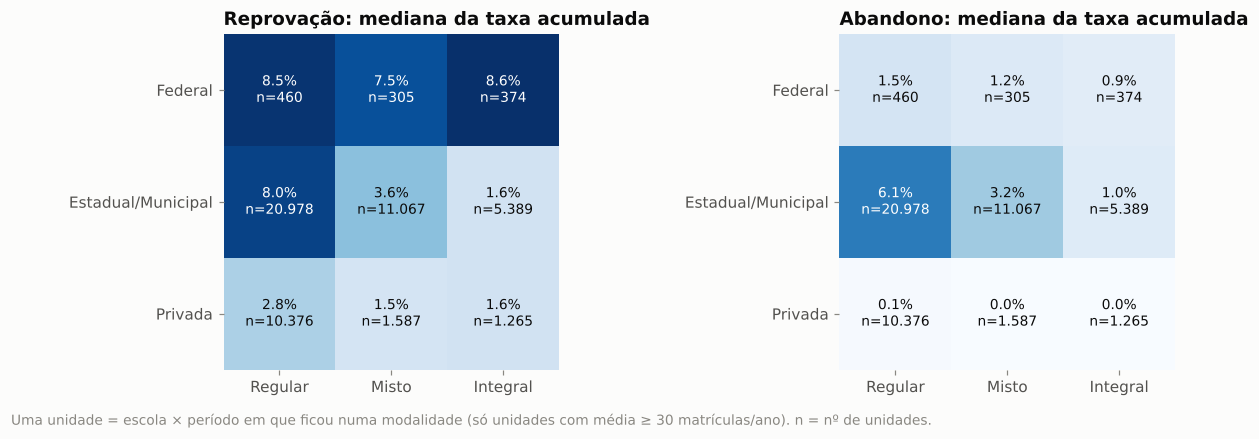

Ano mediano dos períodos em cada célula (mostra quão recentes são as integrais):


modalidade,Regular,Misto,Integral
dependencia,,,
Federal,2018.0,2021.0,2020.0
Estadual/Municipal,2017.5,2022.0,2023.0
Privada,2018.0,2022.5,2023.0


In [ ]:
# Taxa acumulada por escola × período em cada modalidade (unidade do abstract)
acc = (df.groupby(["escola", "dependencia", "modalidade"], observed=True)
         .agg(mat=("mat", "sum"), rep=("rep", "sum"), abn=("abn", "sum"), anos=("ano", "nunique"),
              ano_mediano=("ano", "median"))
         .reset_index())
acc["Reprovação"] = acc["rep"] / acc["mat"] * 100
acc["Abandono"] = acc["abn"] / acc["mat"] * 100
acc = acc[acc["mat"] / acc["anos"] >= MIN_MAT]

med = acc.pivot_table(index="dependencia", columns="modalidade", values=["Reprovação", "Abandono"],
                      aggfunc="median", observed=True)
n_cel = acc.pivot_table(index="dependencia", columns="modalidade", values="escola", aggfunc="count", observed=True)
ano_med = acc.pivot_table(index="dependencia", columns="modalidade", values="ano_mediano", aggfunc="median", observed=True)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, t in zip(axs, ["Reprovação", "Abandono"]):
    m = med[t].loc[ORDEM_DEP, ORDEM_MOD]
    im = ax.imshow(m.values, cmap="Blues", vmin=0, vmax=np.nanmax(med.values))
    for i in range(3):
        for j in range(3):
            v, n = m.values[i, j], n_cel.loc[ORDEM_DEP[i], ORDEM_MOD[j]]
            cor_txt = "#ffffff" if v > 0.55 * np.nanmax(med.values) else TINTA
            ax.text(j, i, f"{v:.1f}%\nn={n:,}".replace(",", "."), ha="center", va="center", fontsize=9, color=cor_txt)
    ax.set_xticks(range(3), ORDEM_MOD)
    ax.set_yticks(range(3), ORDEM_DEP)
    ax.grid(False)
    ax.set_title(f"{t}: mediana da taxa acumulada")
    for s in ax.spines.values():
        s.set_visible(False)
fig.text(0.01, -0.03, f"Uma unidade = escola × período em que ficou numa modalidade (só unidades com média ≥ {MIN_MAT} matrículas/ano). n = nº de unidades.", color=MUDO, fontsize=9)
fig.tight_layout()
salvar(fig, "D2_heatmap_mediana_acumulada")
plt.show()

print("Ano mediano dos períodos em cada célula (mostra quão recentes são as integrais):")
ano_med.loc[ORDEM_DEP, ORDEM_MOD]

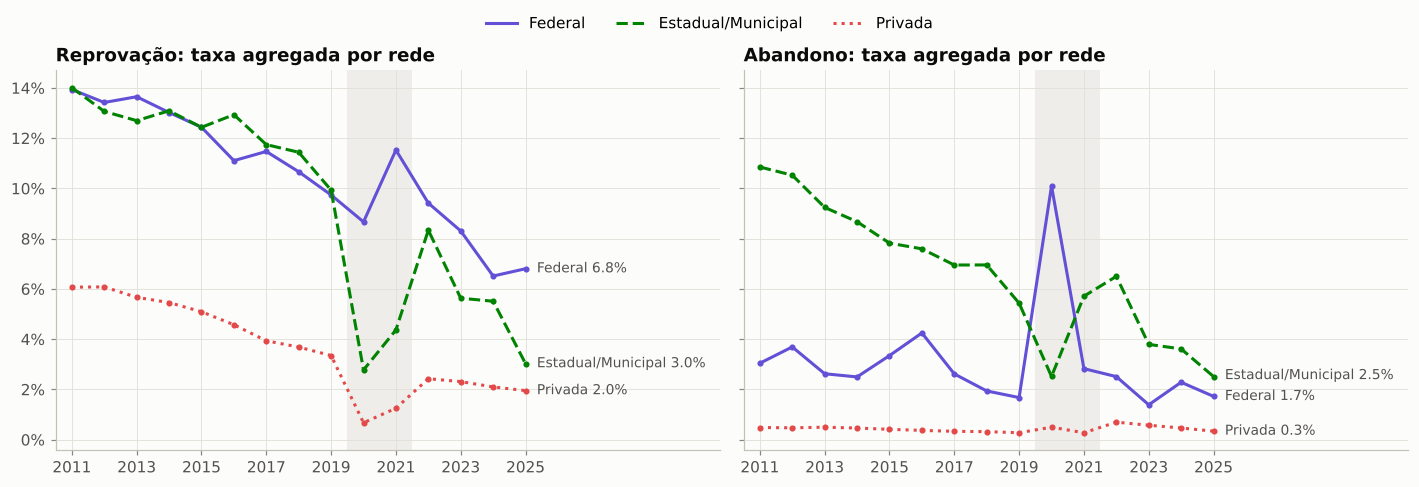

Reprovação                            Abandono                           
dependencia    Federal Estadual/Municipal Privada  Federal Estadual/Municipal Privada
ano                                                                                  
2011              13.9               14.0     6.1      3.0               10.9     0.5
2012              13.4               13.1     6.1      3.7               10.5     0.5
2013              13.6               12.7     5.7      2.6                9.2     0.5
2014              13.0               13.1     5.5      2.5                8.7     0.5
2015              12.4               12.4     5.1      3.3                7.8     0.4
2016              11.1               12.9     4.6      4.2                7.6     0.4
2017              11.5               11.7     3.9      2.6                7.0     0.3
2018              10.7               11.4     3.7      1.9                7.0     0.3
2019               9.7                9.9     3.3      1.7                5.4     0.3
2020               8.7                2.8     0.7     10.1                2.5     0.5
2021              11.5                4.4     1.2      2.8                5.7     0.3
2022               9.4                8.3     2.4      2.5                6.5     0.7
2023               8.3                5.6     2.3      1.4                3.8     0.6
2024               6.5                5.5     2.1      2.3                3.6     0.5
2025               6.8                3.0     2.0      1.7                2.5     0.3

In [ ]:
aggd = df.groupby(["ano", "dependencia"], observed=True)[["mat", "rep", "abn"]].sum()
aggd["Reprovação"] = aggd["rep"] / aggd["mat"] * 100
aggd["Abandono"] = aggd["abn"] / aggd["mat"] * 100

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, t in zip(axs, ["Reprovação", "Abandono"]):
    tab = aggd[t].unstack()
    sombrear_pandemia(ax)
    for d in ORDEM_DEP:
        ax.plot(tab.index, tab[d], color=COR_DEP[d], ls=ESTILO_DEP[d], marker="o", ms=3)
        rotulo_final(ax, tab.index[-1], tab[d].iloc[-1], f"{d} {tab[d].iloc[-1]:.1f}%", COR_DEP[d])
    ax.set_title(f"{t}: taxa agregada por rede")
    ax.set_xlim(2010.5, 2031)
    ax.set_xticks(range(2011, 2026, 2))
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
fig.legend([plt.Line2D([], [], color=COR_DEP[d], ls=ESTILO_DEP[d], lw=2) for d in ORDEM_DEP], ORDEM_DEP,
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
salvar(fig, "D3_taxas_por_ano_dependencia")
plt.show()
aggd[["Reprovação", "Abandono"]].unstack().round(1)

## E. Contexto extra para decidir o recorte

### E1. O que acontece com uma escola quando ela vira integral?

Esta é a comparação mais próxima da pergunta do título ("does the expansion really affect performance?"). Seleção:
- escolas da rede Estadual/Municipal que foram **Regulares por pelo menos 2 anos** e depois ficaram **Integrais** (o ano 0 é o primeiro ano integral);
- eixo x = anos relativos à mudança (−4 a +4).

Duas curvas:
- **Bruta:** taxa agregada das escolas que mudaram.
- **Ajustada pelo ano e pela UF:** taxa da escola menos a taxa das escolas regulares da mesma UF no mesmo ano. Isso tira a queda geral das taxas ao longo do tempo e o peso da pandemia (muitas escolas mudaram em 2020–2022).

Mesmo ajustada, a curva **não prova causa**: as escolas escolhidas para virar integrais podem já estar melhorando (veja se a curva ajustada cai antes do ano 0).

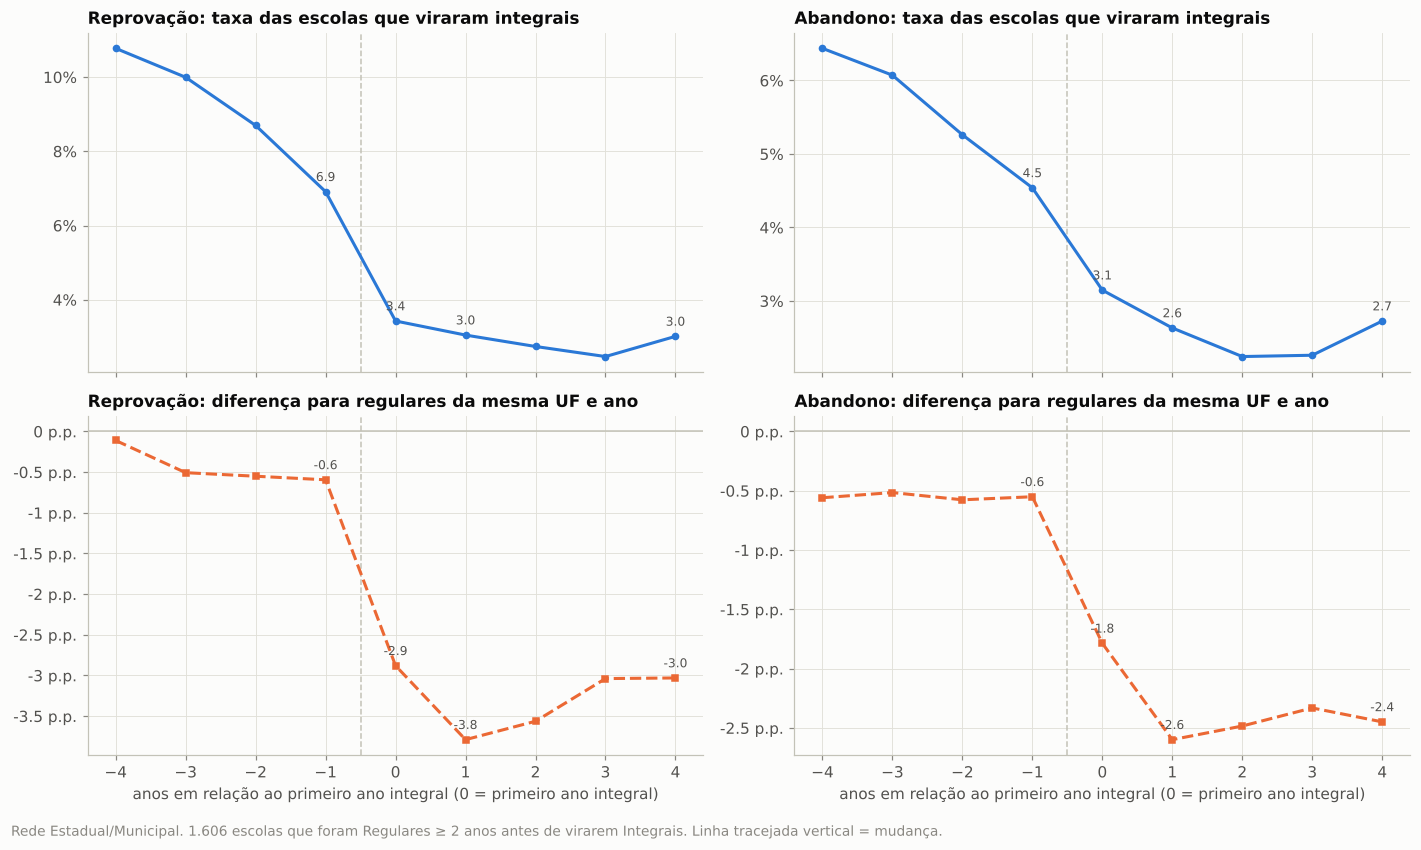

Ano da mudança (quantas escolas viraram integrais em cada ano):
t0
2013     53
2014     76
2015     38
2016     33
2017     94
2018    109
2019     86
2020    230
2021    368
2022    265
2023     82
2024     60
2025    112


,escolas,Reprovação bruta,Reprovação ajustada,Abandono bruto,Abandono ajustado
k,,,,,
-4,1428,10.77,-0.11,6.44,-0.56
-3,1513,10.00,-0.51,6.07,-0.52
-2,1573,8.70,-0.55,5.26,-0.58
-1,1572,6.91,-0.59,4.54,-0.55
0,1606,3.43,-2.88,3.15,-1.79
1,1477,3.05,-3.79,2.63,-2.60
2,1412,2.74,-3.56,2.24,-2.48
3,1324,2.47,-3.04,2.26,-2.33
4,1054,3.01,-3.03,2.73,-2.45


In [ ]:
s = em.sort_values(["escola", "ano"])
t0 = s[s["modalidade"] == "Integral"].groupby("escola")["ano"].min().rename("t0")
sub = s.merge(t0, left_on="escola", right_index=True)
sub["k"] = sub["ano"] - sub["t0"]
pre = sub[sub["k"] < 0]
regular_antes = pre.groupby("escola")["modalidade"].apply(lambda x: (x == "Regular").all()) & (pre.groupby("escola").size() >= 2)
ev = sub[sub["escola"].isin(regular_antes[regular_antes].index) & sub["k"].between(-4, 4)].copy()

# Referência: escolas regulares Est/Mun da mesma UF e ano que NUNCA foram integrais
nunca = em[~em["escola"].isin(t0.index) & (em["modalidade"] == "Regular")]
ref = nunca.groupby(["uf", "ano"])[["mat", "rep", "abn"]].sum()
ref["ref_rep"] = ref["rep"] / ref["mat"]
ref["ref_abn"] = ref["abn"] / ref["mat"]
ev = ev.merge(ref[["ref_rep", "ref_abn"]], left_on=["uf", "ano"], right_index=True, how="left")
ev["rep_esp"] = ev["mat"] * ev["ref_rep"]
ev["abn_esp"] = ev["mat"] * ev["ref_abn"]

e = ev.groupby("k")[["mat", "rep", "abn", "rep_esp", "abn_esp"]].sum()
estudo = pd.DataFrame({
    "escolas": ev.groupby("k")["escola"].nunique(),
    "Reprovação bruta": e["rep"] / e["mat"] * 100,
    "Reprovação ajustada": (e["rep"] - e["rep_esp"]) / e["mat"] * 100,
    "Abandono bruto": e["abn"] / e["mat"] * 100,
    "Abandono ajustado": (e["abn"] - e["abn_esp"]) / e["mat"] * 100,
})

fig, axs = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
for j, (rot, br, aj) in enumerate([("Reprovação", "Reprovação bruta", "Reprovação ajustada"),
                                   ("Abandono", "Abandono bruto", "Abandono ajustado")]):
    for i, (col, cor, mk, ls, unidade, titulo) in enumerate([
            (br, "#2a78d6", "o", "-", "%", f"{rot}: taxa das escolas que viraram integrais"),
            (aj, "#eb6834", "s", "--", " p.p.", f"{rot}: diferença para regulares da mesma UF e ano")]):
        ax = axs[i, j]
        ax.axvline(-0.5, color=EIXO, lw=1, ls="--")
        if i == 1:
            ax.axhline(0, color=EIXO, lw=1)
        ax.plot(estudo.index, estudo[col], color=cor, marker=mk, ms=4, ls=ls)
        for k, v in estudo[col].items():
            if k in (-1, 0, 1, 4):
                ax.annotate(f"{v:+.1f}" if i else f"{v:.1f}", (k, v), xytext=(0, 7), textcoords="offset points",
                            ha="center", fontsize=8, color=TINTA2)
        ax.set_title(titulo, fontsize=11)
        ax.yaxis.set_major_formatter(lambda v, _, u=unidade: f"{v:.1f}{u}".replace(".0" + u, u) if u.strip() else f"{v:.0f}{u}")
        ax.set_xticks(range(-4, 5))
        if i == 1:
            ax.set_xlabel("anos em relação ao primeiro ano integral (0 = primeiro ano integral)", color=TINTA2)
fig.text(0.01, -0.02, f"Rede Estadual/Municipal. {ev['escola'].nunique():,} escolas que foram Regulares ≥ 2 anos antes de virarem Integrais. Linha tracejada vertical = mudança.".replace(",", "."),
         color=MUDO, fontsize=9)
fig.tight_layout()
salvar(fig, "E1_antes_depois_integral")
plt.show()

print("Ano da mudança (quantas escolas viraram integrais em cada ano):")
print(ev.groupby("escola")["t0"].first().value_counts().sort_index().to_string())
estudo.round(2)

### E2. Onde estão as escolas integrais?

A expansão não é uniforme. Se ela se concentra em poucas regiões/UFs, parte das diferenças entre modalidades pode ser diferença entre estados.

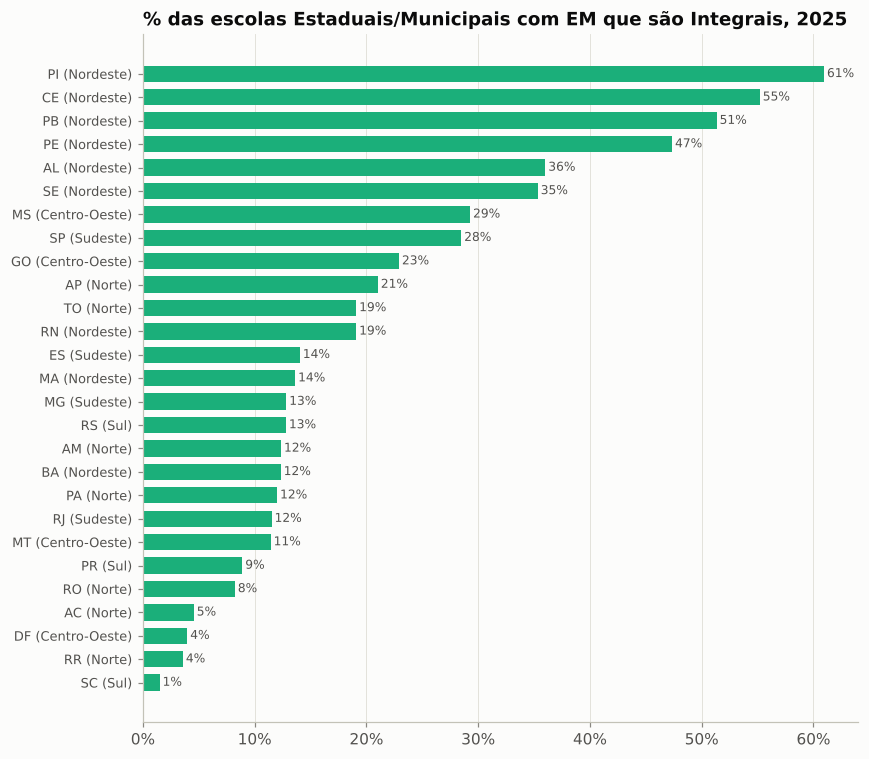

% integral por localização (Est/Mun), por ano:


localizacao,Rural,Urbana
ano,,
2011,3.0,1.1
2012,3.5,1.8
2013,3.0,2.3
2014,3.6,3.3
2015,4.1,4.0
2016,3.7,4.6
2017,4.4,5.6
2018,4.4,6.9
2019,4.7,8.3


In [ ]:
ult = em[em["ano"] == em["ano"].max()]
por_uf = (ult.assign(integral=ult["modalidade"].eq("Integral"))
             .groupby(["regiao", "uf"], observed=True)["integral"].mean().mul(100).sort_values())

fig, ax = plt.subplots(figsize=(8, 7))
barras = ax.barh(range(len(por_uf)), por_uf.values, color="#1baf7a", height=0.7)
ax.bar_label(barras, labels=[f"{v:.0f}%" for v in por_uf.values], fontsize=8, color=TINTA2, padding=2)
ax.set_yticks(range(len(por_uf)), [f"{uf} ({reg})" for reg, uf in por_uf.index], fontsize=8.5)
ax.set_title(f"% das escolas Estaduais/Municipais com EM que são Integrais, {em['ano'].max()}")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.grid(axis="y", visible=False)
fig.tight_layout()
salvar(fig, "E2_integral_por_uf")
plt.show()

loc_reg = (em.assign(integral=em["modalidade"].eq("Integral"))
             .pivot_table(index="ano", columns="localizacao", values="integral", aggfunc="mean") * 100)
print("% integral por localização (Est/Mun), por ano:")
loc_reg.round(1)

### E3. Porte das escolas por modalidade

Escolas integrais são menores? Se sim, isso explica por que a fatia de **escolas** integrais é maior que a fatia de **matrículas**, e é um fator de confusão (escolas menores tendem a ter outro perfil).

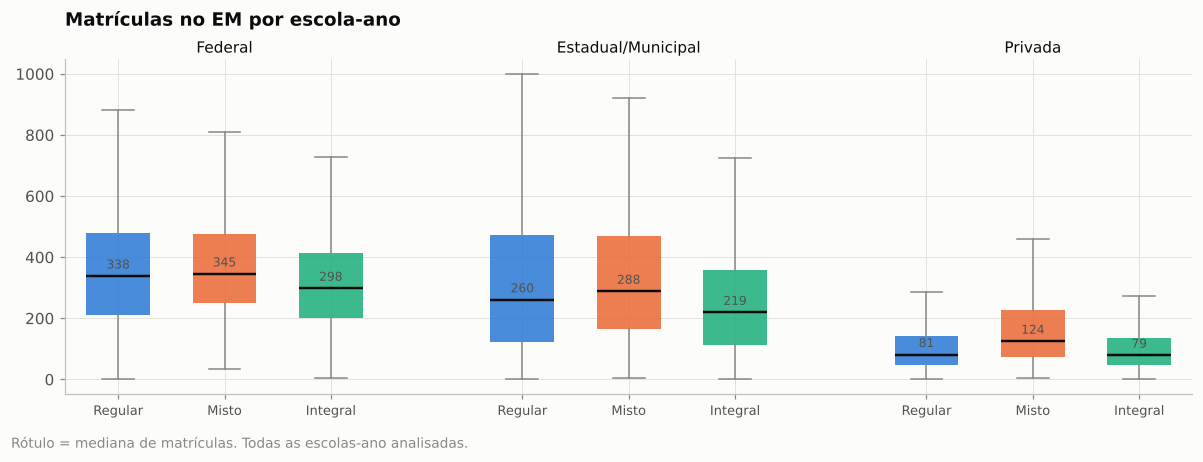

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
pos = 0
xt, xl = [], []
for d in ORDEM_DEP:
    for m in ORDEM_MOD:
        x = df.loc[(df["dependencia"] == d) & (df["modalidade"] == m), "mat"]
        if len(x) == 0:
            continue
        bp = ax.boxplot([x], positions=[pos], widths=0.6, patch_artist=True, showfliers=False,
                        medianprops=dict(color=TINTA, lw=1.6), whiskerprops=dict(color=MUDO),
                        capprops=dict(color=MUDO), boxprops=dict(lw=0))
        bp["boxes"][0].set_facecolor(COR_MOD[m]); bp["boxes"][0].set_alpha(0.85)
        ax.annotate(f"{x.median():.0f}", (pos, x.median()), xytext=(0, 5), textcoords="offset points",
                    ha="center", fontsize=8, color=TINTA2)
        xt.append(pos); xl.append(m)
        pos += 1
    pos += 0.8
ax.set_xticks(xt, xl, fontsize=8.5)
for k, d in enumerate(ORDEM_DEP):
    ax.annotate(d, (k * 3.8 + 1, 1.02), xycoords=("data", "axes fraction"), ha="center", fontsize=10, color=TINTA)
ax.set_title("Matrículas no EM por escola-ano", pad=22)
fig.text(0.01, -0.03, "Rótulo = mediana de matrículas. Todas as escolas-ano analisadas.", color=MUDO, fontsize=9)
fig.tight_layout()
salvar(fig, "E3_porte_por_modalidade")
plt.show()

### E4. Composição: quanto as diferenças vêm da rede e quanto vêm da modalidade?

Tabela de apoio: participação de cada dependência dentro de cada modalidade, por ano. Se as integrais de 2011 eram quase todas federais e as de 2025 são quase todas estaduais, comparar "integral × regular" no período todo mistura redes diferentes.

In [ ]:
comp = (df[df["modalidade"] == "Integral"]
          .pipe(lambda x: pd.crosstab(x["ano"], x["dependencia"], normalize="index") * 100))
comp.round(1)

dependencia,Federal,Estadual/Municipal,Privada
ano,,,
2011,13.8,54.7,31.5
2012,12.6,61.3,26.1
2013,13.0,60.3,26.7
2014,11.3,65.8,22.9
2015,13.6,66.8,19.6
2016,14.4,66.0,19.5
2017,14.1,68.3,17.6
2018,12.7,71.4,15.9
2019,11.3,72.9,15.9


## F. Resumo para decidir o recorte

Escrito depois de rodar o notebook. Números arredondados vêm das tabelas acima.

### O que os dados mostram (números deste notebook)

1. **A expansão é real e concentrada.** Na rede Estadual/Municipal, as escolas integrais passaram de 1,4% (2011) para 20,9% (2025) das escolas com EM. Isso confirma o número do abstract ("about 1% to over 20%"). Em matrículas, o integral vai de 1,3% para 14,6% do total do EM. A expansão é muito desigual entre estados: em 2025, PI 61%, CE 55%, PB 51% e PE 47%, contra SC 1%, DF 4% e RR 4%.
2. **As integrais têm taxas menores em todos os anos, mas a diferença diminuiu.** Abandono agregado, Integral × Regular: 1,3% × 9,6% em 2011 e 1,3% × 2,5% em 2025. Reprovação: 7,2% × 13,2% em 2011 e 1,9% × 3,4% em 2025. A queda geral das taxas veio principalmente das regulares.
3. **A correlação é fraca.** Spearman entre % de matrícula integral e a taxa (escolas com ≥ 30 matrículas):
   - todas as redes: −0,12 (reprovação) e −0,04 (abandono);
   - Estadual/Municipal: −0,23 e −0,23 (ε² ≈ 0,07, ou seja, a modalidade acompanha cerca de 7% da variação entre escolas);
   - Federal e Privada: praticamente zero.
4. **Escolas que viraram integrais (1.606, rede Estadual/Municipal).** Comparadas com as regulares da mesma UF e ano, elas estavam cerca de 0,6 p.p. abaixo antes da mudança, de forma estável. Depois da mudança a diferença passa para −3,8 p.p. em reprovação e −2,6 p.p. em abandono no 1º ano, e fica perto de −3,0 e −2,4 p.p. no 4º ano. Não há tendência de queda antes da mudança.
5. **Problema na rede Federal em 2025.** Das 290 escolas federais integrais em 2024, 94 deixaram de ser integrais em 2025 (71 viraram Mistas), com proporção integral mediana de 0,40. Uma mudança desse tamanho em um ano parece mudança de registro no Censo, não nas escolas.
6. **Quem são as integrais mudou.** Em 2011, 55% das escolas integrais eram estaduais/municipais e 32% privadas. Em 2025, 83% são estaduais/municipais.

### Hipóteses (não testadas aqui)

- A queda depois de virar integral pode refletir **seleção** (as redes escolhem escolas com mais chance de sucesso), **mudança no público** (alunos que não podem estudar em tempo integral saem para outras escolas antes de serem contados como abandono) ou **critérios de aprovação** diferentes. Um teste possível com a base atual: ver se a matrícula da escola cai depois da mudança.
- Taxas de rendimento medem fluxo (passou, reprovou, saiu), não aprendizagem.

### Recomendações para o recorte do pôster

- **Focar na rede Estadual/Municipal.** É onde está a política e onde aparece a associação. Federal e Privada entram como contexto, em uma figura só.
- **Três figuras candidatas:** A2 (expansão por rede), B3 ou B2 (diferença Integral − Regular encolhendo) e E1 (antes e depois, ajustado). A E1 é a que mais se aproxima da pergunta do título.
- **Cuidado com o boxplot acumulado do abstract (D2).** Ele compara períodos de anos diferentes: o ano mediano das regulares é 2017,5 e o das integrais é 2023. Parte da diferença é só o tempo. Se usar, dizer isso na legenda.
- **Não usar Federal 2025** (ou sinalizar) até confirmar a questão do registro.
- **Sombrear ou comentar 2020–2021** em qualquer gráfico temporal.
